# 02-1) 훈련 세트와 테스트 세트

> 핵심 키워드: `지도 학습`, `비지도 학습`, `훈련 세트`, `테스트 세트`

**_"지도 학습과 비지도 학습의 차이를 배운다. 모델을 훈련시키는 훈련 세트와 모델을 평가하기 위한 테스트 세트로 데이터를 나눠서 학습한다."_**

## 지도 학습과 비지도 학습

- 지도 학습, supervised learning
    - 데이터와 정답을 입력(input | 데이터)과 타깃(target | 정답)이라 한다.
        - input + target => 훈련 데이터(training data)
    - 정답(타깃)이 있으니 알고리즘이 정답을 맞히는 것을 학습한다.
    > _"입력과 타깃을 전달하여 모델을 훈련한 다음 새로운 데이터를 예측하는 데 활용한다"_
- 비지도 학습, unsupervised learning
    - 비지도 학습 알고리즘은 타깃 없이 입력 데이터만 사용한다.
    - 정답을 사용하지 않으므로 무언가를 맞힐 수 없으나, 대신 데이터를 잘 파악하거나 변형하는데 도움이 된다.
    > _"타깃 데이터가 없다. 따라서 무엇을 예측하는 것이 아니라 입력 데이터에서 어떤 패턴을 찾는 데 주로 활용한다"_

```mermaid
graph TD
    KNN([k-최근접 이웃]) --- SL([지도학습])
    SL --- ML[머신러닝]
    UL([비지도학습]) --- ML
    ML --- RL([강화학습])
```

$$
\text{49개 생선}\left\{\vphantom{\begin{matrix}1\\1\\\vdots\\0\end{matrix}}\right.
\overbrace{
  \overbrace{
    \begin{bmatrix}
      \overbrace{25.4}^{\text{길이 특성}} & \overbrace{242.0}^{\text{무게 특성}} \\
      26.3 & 290.0 \\
      \vdots & \vdots \\
      15.0 & 19.9
    \end{bmatrix}
  }^{\text{입력}}
  \quad
  \overbrace{
    \begin{bmatrix} 1 \\ 1 \\ \vdots \\ 0 \end{bmatrix}
  }^{\text{타깃}}
}^{\text{훈련 데이터}}
$$

## 훈련 세트와 테스트 세트

- 훈련 세트(train set)
  - 훈련에 사용되는 데이터
  > _"보통 훈련 세트가 클수록 좋다. 따라서 테스트 세트를 제외한 모든 데이터를 사용한다"_
- 테스트 세트(test set)
  - 평가에 사용하는 데이터
  > _"전체 데이터에서 2~30%를 테스트 세트로 사용하는 경우가 많다. 전체 데이터가 아추 크다면 1%만 덜어내도 충분하다"_

> 훈련에 사용하는 데이터로 모델을 평가하는 것을 적절하지 않다. 훈련할 때 사용하지 않은 데이터로 평가해야 한다.

- 샘플링 편향(sampling bias)
  - 훈련 세트와 테스트 세트에 샘플이 골고루 섞여 않으면 샘플링이 한쪽으로 치우쳐 있다고 말할 수 있다.
    - ex) 훈련 세트에 도미 데이터만 있고, 평가 데이터에 빙어만 있는 경우


In [2]:
from operator import index

fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0,
                31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0,
                35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8,
                10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0,
                500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0,
                700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7,
                7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [7]:
fish_data = [[l, w] for l, w in zip(fish_length, fish_weight)]
fish_target = [1]*35 + [0]*14

In [11]:
import numpy as np

# 파이썬 리스트를 numpy 배열로 바꾸기
input_arr = np.array(fish_data)
target_arr = np.array(fish_target)

In [26]:
input_arr.shape # (샘플 수, 특성 수)

(49, 2)

In [10]:

np.random.seed(42)
index = np.arange(49)
np.random.shuffle(index)

print(index)

[13 45 47 44 17 27 26 25 31 19 12  4 34  8  3  6 40 41 46 15  9 16 24 33
 30  0 43 32  5 29 11 36  1 21  2 37 35 23 39 10 22 18 48 20  7 42 14 28
 38]


In [13]:
# numpy의 배열 인덱싱(array indexing) 활용
# 1개의 인덱스가 아닌 여러 개의 인덱스로 한 번에 여러 개의 원소를 선택할 수 있다.

train_input = input_arr[index[:35]]
train_target = target_arr[index[:35]]

In [14]:
print(input_arr[13], train_input[0])

[ 32. 340.] [ 32. 340.]


In [15]:
test_input = input_arr[index[35:]]
test_target = target_arr[index[35:]]

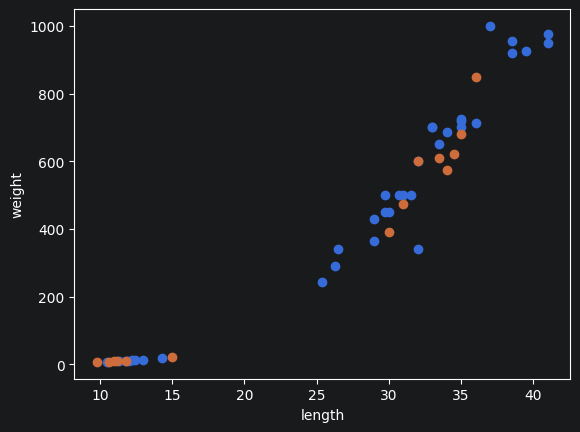

In [17]:
# 훈련 세트와 테스트 세트에 도미와 빙어가 잘 섞여 있는지 산점도로 그려서 확인해보기

import matplotlib.pyplot as plt
plt.scatter(train_input[:, 0], train_input[:, 1])
plt.scatter(test_input[:, 0], test_input[:, 1])
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [20]:
from sklearn.neighbors import KNeighborsClassifier

kn = KNeighborsClassifier()

# fit 메서드를 실행할 때마다 KNeighborsClassifier 클래스의 객체는 이전에 학습한 모든 것을 잃어버린다
kn.fit(train_input, train_target) # 훈련
#      ↑ 입력(X): 샘플×특성   ↑ 타깃(y): 따로 전달
kn.score(test_input, test_target) # 테스트(평가)

1.0

In [23]:
kn.predict(test_input) # 테스트 세트의 예측 결과

array([0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0])

In [24]:
test_target # 테스트 세트의 실제 타깃

array([0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0])